In [64]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score , confusion_matrix
import pandas as pd
data= pd.read_csv("../data/processed/f1_dataset_final.csv") 
print(data.keys())

data["top3"] = (data["position_order"] <= 3).astype(int)

# Vérification
print(data.keys())

Index(['driver_id', 'race_id', 'constructor_id', 'date', 'round',
       'position_order', 'driver_avg_position_last_5',
       'driver_top_3_rate_last_5', 'driver_circuit_avg_position',
       'driver_circuit_top3_rate', 'driver_circuit_has_history',
       'constructor_circuit_avg_position', 'constructor_circuit_top3_rate',
       'constructor_avg_position_last5', 'constructor_top3_rate_last5',
       'constructor_mechanical_dnf_rate_last5', 'grid_position',
       'driver_p1_starts', 'driver_dnf_rate'],
      dtype='str')
Index(['driver_id', 'race_id', 'constructor_id', 'date', 'round',
       'position_order', 'driver_avg_position_last_5',
       'driver_top_3_rate_last_5', 'driver_circuit_avg_position',
       'driver_circuit_top3_rate', 'driver_circuit_has_history',
       'constructor_circuit_avg_position', 'constructor_circuit_top3_rate',
       'constructor_avg_position_last5', 'constructor_top3_rate_last5',
       'constructor_mechanical_dnf_rate_last5', 'grid_position',
    

In [ ]:
X=data[['driver_avg_position_last_5',
       'driver_top_3_rate_last_5', 'driver_circuit_avg_position',
       'driver_circuit_top3_rate', 'driver_circuit_has_history',
       'constructor_circuit_avg_position', 'constructor_circuit_top3_rate',
       'constructor_avg_position_last5', 'constructor_top3_rate_last5',
       'constructor_mechanical_dnf_rate_last5', 'grid_position',
       'driver_p1_starts', 'driver_dnf_rate']]

Y=data['top3']
#Si un pilote n'a jamais couru sur un circuit, on peut estimer sa performance à partir de ses 5 dernières courses.
X["driver_circuit_avg_position"] = X["driver_circuit_avg_position"].fillna(
    X["driver_avg_position_last_5"]
)
print(Y.isna().sum)

0       0
1       1
2       0
3       0
4       0
       ..
5430    0
5431    0
5432    0
5433    1
5434    0
Name: top3, Length: 5435, dtype: int64


In [90]:
print(X.shape)
print(X.isna().sum())
print(Y.value_counts())

(5435, 13)
driver_avg_position_last_5                 63
driver_top_3_rate_last_5                   63
driver_circuit_avg_position                63
driver_circuit_top3_rate                 1430
driver_circuit_has_history                  0
constructor_circuit_avg_position         1139
constructor_circuit_top3_rate            1139
constructor_avg_position_last5             44
constructor_top3_rate_last5                44
constructor_mechanical_dnf_rate_last5      44
grid_position                               7
driver_p1_starts                            0
driver_dnf_rate                             0
dtype: int64
top3
0    4634
1     801
Name: count, dtype: int64


In [56]:
data["date"] = pd.to_datetime(data["date"])
print(data["date"].min())
print(data["date"].max())

data_train = data[(data["date"].dt.year <= 2023 )]
print(data_train.keys())
X_train=data_train[['driver_avg_position_last_5',
       'driver_top_3_rate_last_5', 'driver_circuit_avg_position',
       'driver_circuit_top3_rate', 'driver_circuit_has_history',
       'constructor_circuit_avg_position', 'constructor_circuit_top3_rate',
       'constructor_avg_position_last5', 'constructor_top3_rate_last5',
       'constructor_mechanical_dnf_rate_last5', 'grid_position',
       'driver_p1_starts', 'driver_dnf_rate']]
print(X_train)
Y_train=data_train['top3']
print(Y_train)
data_test = data[(data["date"].dt.year >= 2024 )]
X_test=data_test[['driver_avg_position_last_5',
       'driver_top_3_rate_last_5', 'driver_circuit_avg_position',
       'driver_circuit_top3_rate', 'driver_circuit_has_history',
       'constructor_circuit_avg_position', 'constructor_circuit_top3_rate',
       'constructor_avg_position_last5', 'constructor_top3_rate_last5',
       'constructor_mechanical_dnf_rate_last5', 'grid_position',
       'driver_p1_starts', 'driver_dnf_rate']]
print(X_train)
Y_test=data_test['top3']
print(Y_train)


2014-03-16 00:00:00
2026-09-26 00:00:00
Index(['driver_id', 'race_id', 'constructor_id', 'date', 'round',
       'position_order', 'driver_avg_position_last_5',
       'driver_top_3_rate_last_5', 'driver_circuit_avg_position',
       'driver_circuit_top3_rate', 'driver_circuit_has_history',
       'constructor_circuit_avg_position', 'constructor_circuit_top3_rate',
       'constructor_avg_position_last5', 'constructor_top3_rate_last5',
       'constructor_mechanical_dnf_rate_last5', 'grid_position',
       'driver_p1_starts', 'driver_dnf_rate', 'top3'],
      dtype='str')
      driver_avg_position_last_5  driver_top_3_rate_last_5  \
0                            NaN                       NaN   
1                            NaN                       NaN   
2                            NaN                       NaN   
3                            NaN                       NaN   
4                            NaN                       NaN   
...                          ...                 

In [57]:
#print(X_train.isna().sum())
X_train = X_train.copy()
X_test = X_test.copy()
# 1. Remplacements basés sur des features similaires

fallbacks = {
    "driver_circuit_avg_position": "driver_avg_position_last_5",
    "driver_circuit_top3_rate": "driver_top_3_rate_last_5",
    "constructor_circuit_avg_position": "constructor_avg_position_last5",
    "constructor_circuit_top3_rate": "constructor_top3_rate_last5"
}

for target, source in fallbacks.items():
    X_train[target] = X_train[target].fillna(X_train[source])
    X_test[target] = X_test[target].fillna(X_test[source])


# 2. Calculer les médianes uniquement sur Train
train_medians = X_train.median()
# 3. Remplacer les NaN restants

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)


# 4. Vérifier

print("NaN dans Train :", X_train.isna().sum().sum())
print("NaN dans Test :", X_test.isna().sum().sum())
print(X_train.isna().sum())

NaN dans Train : 0
NaN dans Test : 0
driver_avg_position_last_5               0
driver_top_3_rate_last_5                 0
driver_circuit_avg_position              0
driver_circuit_top3_rate                 0
driver_circuit_has_history               0
constructor_circuit_avg_position         0
constructor_circuit_top3_rate            0
constructor_avg_position_last5           0
constructor_top3_rate_last5              0
constructor_mechanical_dnf_rate_last5    0
grid_position                            0
driver_p1_starts                         0
driver_dnf_rate                          0
dtype: int64


In [ ]:
rf=RandomForestClassifier(n_estimators=100 ,max_depth= None,random_state= 42 )
rf.fit(X_train,Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [69]:
Y_pred=rf.predict(X_test)
print(Y_pred)
acc = accuracy_score(Y_test , Y_pred)
print(F"accurcy{acc}")

cm = confusion_matrix(Y_test, Y_pred)
print(F"confusion matrix {cm}")



[0 0 0 ... 0 0 0]
accurcy0.8967391304347826
confusion matrix [[1047   52]
 [  81  108]]


In [ ]:
#on compare la perfeormance selon le nbre d'arbres
best_acc = 0 
best_n = None 
for n in [20, 50, 100, 200]:
    model = RandomForestClassifier(
        n_estimators=n , 
        random_state=42 
    )

    model.fit(X_train, Y_train) 
    pred = model.predict(X_test) 
    acc_n = accuracy_score(Y_test , pred) 
    print(f"n_estimators={n}: accuracy= {acc_n:.4f}")
    if acc_n> best_acc:
        best_acc = acc_n 
        best_n = n 

print(f"\n Best n_estimators selected: ", best_n)
        

n_estimators=20: accuracy= 0.8929
n_estimators=50: accuracy= 0.8960
n_estimators=100: accuracy= 0.8967
n_estimators=200: accuracy= 0.8983

 Best n_estimators selected:  200


[0.1053071  0.08826483 0.06555438 0.03419621 0.00612286 0.06409032
 0.0752643  0.10416634 0.09778354 0.01982641 0.22338989 0.04672716
 0.06930666]
[0.00612286 0.01982641 0.03419621 0.04672716 0.06409032 0.06555438
 0.06930666 0.0752643  0.08826483 0.09778354 0.10416634 0.1053071
 0.22338989]


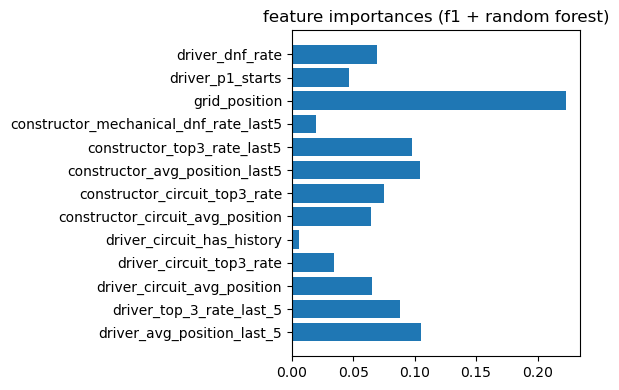

In [77]:
import numpy as np
import matplotlib.pyplot as plt
importances = rf.feature_importances_ 
idx = np.argsort(importances) 
print(importances)
print(importances[idx])

features=X_train.keys()
plt.figure(figsize=(6, 4 ))
plt.barh(features, importances)
plt.title("feature importances (f1 + random forest)")

plt.tight_layout() 
plt.show()

In [ ]:
#pred les prob des drivers
Y_proba = rf.predict_proba(X_test)
#renvoie 2 colonnes proba top3 et proba hors top3
print(Y_proba[:5])
proba_top3 = Y_proba[:, 1]
results = data_test[["race_id", "driver_id"]].copy()
results["proba_top3"] = proba_top3

print(results.head(10))

[[0.83 0.17]
 [0.94 0.06]
 [1.   0.  ]
 [0.67 0.33]
 [1.   0.  ]]
      race_id  driver_id  proba_top3
4147     1121          1        0.17
4148     1121          4        0.06
4149     1121        807        0.00
4150     1121        815        0.33
4151     1121        817        0.00
4152     1121        822        0.02
4153     1121        825        0.00
4154     1121        830        0.82
4155     1121        832        0.22
4156     1121        839        0.00


In [80]:
top3_predictions = (
    results.sort_values(
        ["race_id", "proba_top3"],
        ascending=[True, False]
    )
    .groupby("race_id")
    .head(3)
)

print(top3_predictions.head(15))

      race_id  driver_id  proba_top3
4154     1121        830        0.82
4159     1121        844        0.62
4150     1121        815        0.33
4174     1122        830        0.93
4178     1122        844        0.77
4170     1122        815        0.69
4194     1123        830        0.90
4190     1123        815        0.55
4200     1123        846        0.49
4209     1124        815        0.88
4213     1124        830        0.88
4218     1124        844        0.52
4229     1125        815        0.82
4233     1125        830        0.75
4239     1125        846        0.48


In [ ]:
import pandas as pd
#pour recupere les noms des pilotes dans le graphe ci dessous
drivers = pd.read_csv("../data/raw/drivers.csv")
drivers["driver_name"] = (drivers["forename"] + " " + drivers["surname"])
results = results.merge(
    drivers[["driverId", "driver_name"]],
    left_on="driver_id",
    right_on="driverId",
    how="left"
)

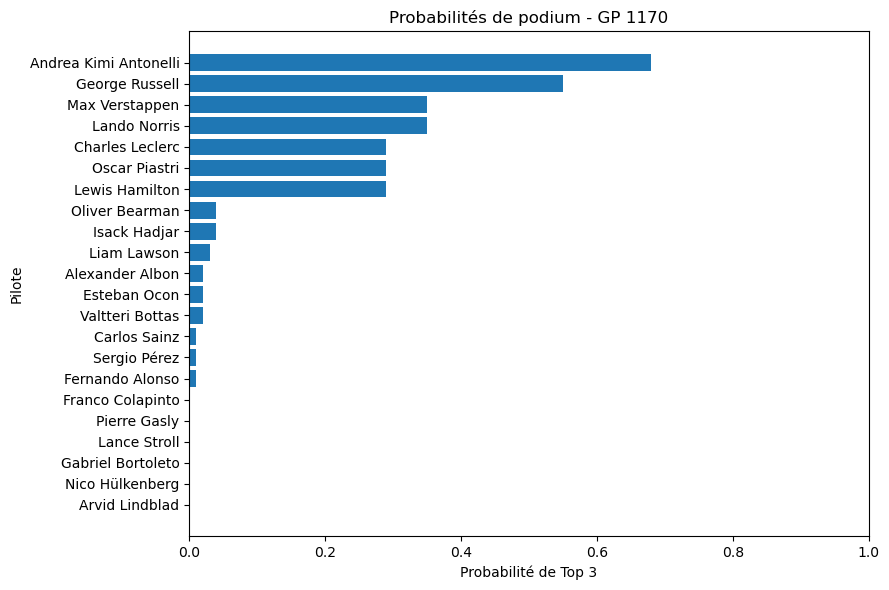

In [89]:
#teste poir un race
race_id = 1170

race_results = (results[results["race_id"] == race_id].sort_values("proba_top3"))
plt.figure(figsize=(9, 6))
plt.barh(race_results["driver_name"],race_results["proba_top3"])

plt.xlabel("Probabilité de Top 3")
plt.ylabel("Pilote")
plt.title(f"Probabilités de podium - GP {race_id}")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
#on compare la perfeormance selon le nbre d'arbres
best_acc = 0 
best_n = None 
for n in [20, 50, 100, 200]:
    model = RandomForestClassifier(
        n_estimators=n , 
        random_state=42 
    )

    model.fit(X_train, Y_train) 
    pred = model.predict(X_test) 
    acc_n = accuracy_score(Y_test , pred) 
    print(f"n_estimators={n}: accuracy= {acc_n:.4f}")
    if acc_n> best_acc:
        best_acc = acc_n 
        best_n = n 

print(f"\n Best n_estimators selected: ", best_n)
        

n_estimators=20: accuracy= 0.8929
n_estimators=50: accuracy= 0.8960
n_estimators=100: accuracy= 0.8967
n_estimators=200: accuracy= 0.8983

 Best n_estimators selected:  200


In [ ]:
#on compare la perfeormance selon le nbre d'arbres
best_acc = 0 
best_n = None 
for n in [20, 50, 100, 200]:
    model = RandomForestClassifier(
        n_estimators=n , 
        random_state=42 
    )

    model.fit(X_train, Y_train) 
    pred = model.predict(X_test) 
    acc_n = accuracy_score(Y_test , pred) 
    print(f"n_estimators={n}: accuracy= {acc_n:.4f}")
    if acc_n> best_acc:
        best_acc = acc_n 
        best_n = n 

print(f"\n Best n_estimators selected: ", best_n)
        

n_estimators=20: accuracy= 0.8929
n_estimators=50: accuracy= 0.8960
n_estimators=100: accuracy= 0.8967
n_estimators=200: accuracy= 0.8983

 Best n_estimators selected:  200
